In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("banglore.csv")
df

,area_type,availability,location,size,society,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,Coomee,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,Theanmp,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,NaN,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,Soiewre,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,NaN,1200,2.0,1.0,51.00
...,...,...,...,...,...,...,...,...,...
13315,Built-up Area,Ready To Move,Whitefield,5 Bedroom,ArsiaEx,3453,4.0,0.0,231.00
13316,Super built-up Area,Ready To Move,Richards Town,4 BHK,NaN,3600,5.0,NaN,400.00
13317,Built-up Area,Ready To Move,Raja Rajeshwari Nagar,2 BHK,Mahla T,1141,2.0,1.0,60.00
13318,Super built-up Area,18-Jun,Padmanabhanagar,4 BHK,SollyCl,4689,4.0,1.0,488.00


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 13320 entries, 0 to 13319
Data columns (total 9 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   area_type     13320 non-null  object 
 1   availability  13320 non-null  object 
 2   location      13319 non-null  object 
 3   size          13304 non-null  object 
 4   society       7818 non-null   object 
 5   total_sqft    13320 non-null  object 
 6   bath          13247 non-null  float64
 7   balcony       12711 non-null  float64
 8   price         13320 non-null  float64
dtypes: float64(3), object(6)
memory usage: 936.7+ KB


In [4]:
df.isnull().sum()

area_type          0
availability       0
location           1
size              16
society         5502
total_sqft         0
bath              73
balcony          609
price              0
dtype: int64

Around 5.5k values are missing from 13k so we can drop the column 

In [5]:
df.drop('society',axis =1,inplace=True)

In [6]:
df.isnull().sum()

area_type         0
availability      0
location          1
size             16
total_sqft        0
bath             73
balcony         609
price             0
dtype: int64

In [7]:
df.dropna(inplace = True)

In [8]:
df.duplicated().sum()

564

In [9]:
df.drop_duplicates(inplace=True)
df.reset_index(inplace=True, drop=True)

In [10]:
df

,area_type,availability,location,size,total_sqft,bath,balcony,price
0,Super built-up Area,19-Dec,Electronic City Phase II,2 BHK,1056,2.0,1.0,39.07
1,Plot Area,Ready To Move,Chikka Tirupathi,4 Bedroom,2600,5.0,3.0,120.00
2,Built-up Area,Ready To Move,Uttarahalli,3 BHK,1440,2.0,3.0,62.00
3,Super built-up Area,Ready To Move,Lingadheeranahalli,3 BHK,1521,3.0,1.0,95.00
4,Super built-up Area,Ready To Move,Kothanur,2 BHK,1200,2.0,1.0,51.00
...,...,...,...,...,...,...,...,...
12141,Super built-up Area,Ready To Move,Bellandur,2 BHK,1262,2.0,2.0,47.00
12142,Super built-up Area,Ready To Move,Green Glen Layout,3 BHK,1715,3.0,3.0,112.00
12143,Built-up Area,Ready To Move,Whitefield,5 Bedroom,3453,4.0,0.0,231.00
12144,Built-up Area,Ready To Move,Raja Rajeshwari Nagar,2 BHK,1141,2.0,1.0,60.00


In [11]:
df.describe()

,bath,balcony,price
count,12146.000000,12146.000000,12146.000000
mean,2.632636,1.582496,107.788264
std,1.241880,0.823384,134.198250
min,1.000000,0.000000,8.000000
25%,2.000000,1.000000,50.000000
50%,2.000000,2.000000,70.000000
75%,3.000000,2.000000,115.000000
max,40.000000,3.000000,2912.000000


In [12]:
df.columns

Index(['area_type', 'availability', 'location', 'size', 'total_sqft', 'bath',
       'balcony', 'price'],
      dtype='object')

In [13]:
numerical = [i for i in df.columns if df[i].dtype != 'O']
categorical = [i for i in df.columns if df[i].dtype == 'O']

In [14]:
print(numerical)
print(categorical)

['bath', 'balcony', 'price']
['area_type', 'availability', 'location', 'size', 'total_sqft']


In [15]:
df['area_type'].value_counts()

Super built-up  Area    7974
Built-up  Area          2289
Plot  Area              1801
Carpet  Area              82
Name: area_type, dtype: int64

These are can be converted by encoding them 

In [16]:
df['availability'].value_counts()

Ready To Move    9639
18-May            277
18-Dec            267
18-Apr            259
18-Aug            187
                 ... 
15-Dec              1
20-Feb              1
16-Jul              1
14-Nov              1
14-Jul              1
Name: availability, Length: 78, dtype: int64

In [17]:
df['location'].value_counts()

Whitefield            497
Sarjapur  Road        352
Electronic City       284
Kanakpura Road        231
Thanisandra           226
                     ... 
Milk Colony             1
Jaladarsini Layout      1
Sundara Nagar           1
Madanayakahalli         1
Abshot Layout           1
Name: location, Length: 1265, dtype: int64

In [18]:
df['size'].value_counts()

2 BHK         4857
3 BHK         3928
4 Bedroom      747
3 Bedroom      515
1 BHK          513
4 BHK          474
2 Bedroom      313
5 Bedroom      257
6 Bedroom      169
1 Bedroom      104
7 Bedroom       68
8 Bedroom       65
5 BHK           36
9 Bedroom       29
6 BHK           23
7 BHK           16
1 RK            13
9 BHK            5
8 BHK            3
10 Bedroom       3
11 Bedroom       2
11 BHK           1
27 BHK           1
43 Bedroom       1
14 BHK           1
12 Bedroom       1
13 BHK           1
Name: size, dtype: int64

We don't need those bedroom and bhk and some remain RK 

In [19]:
df['size'] = df['size'].str.split(" ").str[0]

In [20]:
df['size'].value_counts()

2     5170
3     4443
4     1221
1      630
5      293
6      192
7       84
8       68
9       34
11       3
10       3
27       1
43       1
14       1
12       1
13       1
Name: size, dtype: int64

as bedrooms won't have 27 and 43 in a house generally 4-5 bhk are allowed and remain are to be removed because those are outliers which will influence the best fit line

currently we are allowing until 6bhk

In [21]:
df['size'] = df['size'].astype(int)

In [22]:
drop_idx_lst = df[df['size']>6].index
df.drop(drop_idx_lst,inplace = True)


In [23]:
df.reset_index(drop =True, inplace=True)

it's better to split day and month

In [24]:
df['availability'].unique()

array(['19-Dec', 'Ready To Move', '18-Feb', '18-Nov', '18-May', '20-Dec',
       '17-Oct', '21-Dec', '19-Sep', '20-Sep', '18-Mar', '18-Apr',
       '20-Aug', '19-Mar', '17-Sep', '18-Dec', '17-Aug', '19-Apr',
       '18-Jun', '22-Dec', '22-Jan', '18-Aug', '19-Jan', '17-Jul',
       '18-Jul', '21-Jun', '20-May', '19-Aug', '18-Sep', '17-May',
       '17-Jun', '18-Oct', '21-May', '18-Jan', '20-Mar', '17-Dec',
       '16-Mar', '19-Jun', '22-Jun', '19-Jul', '21-Feb', '19-May',
       '17-Nov', '20-Oct', '20-Jun', '19-Feb', '21-Oct', '21-Jan',
       '17-Mar', '17-Apr', '22-May', '19-Oct', '21-Jul', '21-Nov',
       '21-Mar', '16-Dec', '22-Mar', '20-Jan', '21-Sep', '21-Aug',
       '14-Nov', '19-Nov', '16-Jul', '15-Jun', '20-Nov', '20-Jul',
       '16-Sep', '20-Feb', '15-Dec', '16-Oct', '22-Nov', '15-Aug',
       '17-Jan', '16-Nov', '20-Apr', '16-Jan', '17-Feb', '14-Jul'],
      dtype=object)

In [25]:
df['availability_year'] = df['availability'].str.split("-").str[0]
df['availability_month'] = df['availability'].str.split("-").str[1]

In [26]:
df['availability_year'].replace('Ready To Move', 0,inplace=True)
df['availability_month'].replace(np.nan,'ready to move',inplace=True)

In [27]:
df.drop('availability',axis =1, inplace =True)

In [28]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11949 entries, 0 to 11948
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   area_type           11949 non-null  object 
 1   location            11949 non-null  object 
 2   size                11949 non-null  int32  
 3   total_sqft          11949 non-null  object 
 4   bath                11949 non-null  float64
 5   balcony             11949 non-null  float64
 6   price               11949 non-null  float64
 7   availability_year   11949 non-null  object 
 8   availability_month  11949 non-null  object 
dtypes: float64(3), int32(1), object(5)
memory usage: 793.6+ KB


In [29]:
df['availability_year'].value_counts()

0     9447
18    1542
19     436
20     171
21     159
17     127
22      49
16      13
15       3
14       2
Name: availability_year, dtype: int64

In [30]:
df['availability_month'].value_counts()

ready to move    9447
Dec               650
May               317
Apr               286
Aug               235
Mar               226
Jun               189
Jul               187
Jan               110
Oct                86
Sep                76
Nov                74
Feb                66
Name: availability_month, dtype: int64

In [31]:
df['availability_year'] = df['availability_year'].astype(int)

In [32]:
df['total_sqft'].value_counts()

1200              703
1100              206
1500              187
2400              169
1000              161
                 ... 
78.03Sq. Meter      1
1208.51             1
3300 - 3335         1
1622                1
4689                1
Name: total_sqft, Length: 1962, dtype: int64

In [33]:
df[df['total_sqft'] == '78.03Sq. Meter']

,area_type,location,size,total_sqft,bath,balcony,price,availability_year,availability_month
5454,Built-up Area,1st Phase JP Nagar,1,78.03Sq. Meter,1.0,1.0,63.0,0,ready to move


In [34]:
df['total_sqft1'] = df['total_sqft'].str.split('-').str[0]
df['total_sqft2'] = df['total_sqft'].str.split('-').str[1]

In [35]:
df['total_sqft1'].unique()

array(['1056', '2600', '1440', ..., '1133 ', '774', '4689'], dtype=object)

In [36]:
df['total_sqft2'].unique()

array([nan, ' 2850', ' 8156', ' 1105', ' 1340', ' 1540', ' 1440', ' 1145',
       ' 5002', ' 1195', ' 1130', ' 645', ' 1285', ' 665', ' 666',
       ' 1455', ' 1116', ' 1093', ' 827.31', ' 650', ' 3435', ' 2273',
       ' 3800', ' 5249', ' 1305', ' 980', ' 1252.49', ' 1204', ' 936',
       ' 3360', ' 2882', ' 804', ' 1863', ' 1405', ' 1437', ' 1030',
       ' 4112.19', ' 1315', ' 3019', ' 648', ' 730', ' 1477', ' 3464',
       ' 1500', ' 1199', ' 535', ' 894', ' 670', ' 3250', ' 1290', ' 700',
       ' 440', ' 841', ' 1766', ' 1350', ' 1080', ' 2591', ' 2733',
       ' 624', ' 3324', ' 3335', ' 1630', ' 1700', ' 1249', ' 1595',
       ' 1275', ' 1010', ' 742', ' 1117', ' 958', ' 1300', ' 1950',
       ' 805', ' 934', ' 2467', ' 740', ' 4201', ' 4940', ' 770', ' 722',
       ' 861', ' 985', ' 565', ' 800', ' 1805', ' 1183', ' 2870', ' 1220',
       ' 2090', ' 639', ' 716', ' 803', ' 2790', ' 943', ' 5540', ' 1375',
       ' 615', ' 960', ' 2990', ' 1490', ' 780', ' 1194', ' 810', ' 1670

In [37]:
df['total_sqft2'].fillna(df['total_sqft1'], inplace=True)

In [38]:
drp_lst =  df[df['total_sqft'].astype(str).str.contains('Acre|Guntha|Cents|Perch|Sq|Ground', case=False, na=False)].index

In [39]:
df.drop(drp_lst,inplace=True)
df.reset_index(drop =True, inplace=True)

In [40]:
df

,area_type,location,size,total_sqft,bath,balcony,price,availability_year,availability_month,total_sqft1,total_sqft2
0,Super built-up Area,Electronic City Phase II,2,1056,2.0,1.0,39.07,19,Dec,1056,1056
1,Plot Area,Chikka Tirupathi,4,2600,5.0,3.0,120.00,0,ready to move,2600,2600
2,Built-up Area,Uttarahalli,3,1440,2.0,3.0,62.00,0,ready to move,1440,1440
3,Super built-up Area,Lingadheeranahalli,3,1521,3.0,1.0,95.00,0,ready to move,1521,1521
4,Super built-up Area,Kothanur,2,1200,2.0,1.0,51.00,0,ready to move,1200,1200
...,...,...,...,...,...,...,...,...,...,...,...
11904,Super built-up Area,Bellandur,2,1262,2.0,2.0,47.00,0,ready to move,1262,1262
11905,Super built-up Area,Green Glen Layout,3,1715,3.0,3.0,112.00,0,ready to move,1715,1715
11906,Built-up Area,Whitefield,5,3453,4.0,0.0,231.00,0,ready to move,3453,3453
11907,Built-up Area,Raja Rajeshwari Nagar,2,1141,2.0,1.0,60.00,0,ready to move,1141,1141


In [41]:
df['total_sqft1'] = df['total_sqft1'].astype(float)

In [42]:
df['total_sqft2'] = df['total_sqft2'].astype(float)

In [43]:
df['total_sqft_final'] = (df['total_sqft1'] + df['total_sqft2'])/2
df['total_sqft_final']

0        1056.0
1        2600.0
2        1440.0
3        1521.0
4        1200.0
          ...  
11904    1262.0
11905    1715.0
11906    3453.0
11907    1141.0
11908    4689.0
Name: total_sqft_final, Length: 11909, dtype: float64

In [44]:
df

,area_type,location,size,total_sqft,bath,balcony,price,availability_year,availability_month,total_sqft1,total_sqft2,total_sqft_final
0,Super built-up Area,Electronic City Phase II,2,1056,2.0,1.0,39.07,19,Dec,1056.0,1056.0,1056.0
1,Plot Area,Chikka Tirupathi,4,2600,5.0,3.0,120.00,0,ready to move,2600.0,2600.0,2600.0
2,Built-up Area,Uttarahalli,3,1440,2.0,3.0,62.00,0,ready to move,1440.0,1440.0,1440.0
3,Super built-up Area,Lingadheeranahalli,3,1521,3.0,1.0,95.00,0,ready to move,1521.0,1521.0,1521.0
4,Super built-up Area,Kothanur,2,1200,2.0,1.0,51.00,0,ready to move,1200.0,1200.0,1200.0
...,...,...,...,...,...,...,...,...,...,...,...,...
11904,Super built-up Area,Bellandur,2,1262,2.0,2.0,47.00,0,ready to move,1262.0,1262.0,1262.0
11905,Super built-up Area,Green Glen Layout,3,1715,3.0,3.0,112.00,0,ready to move,1715.0,1715.0,1715.0
11906,Built-up Area,Whitefield,5,3453,4.0,0.0,231.00,0,ready to move,3453.0,3453.0,3453.0
11907,Built-up Area,Raja Rajeshwari Nagar,2,1141,2.0,1.0,60.00,0,ready to move,1141.0,1141.0,1141.0


In [45]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11909 entries, 0 to 11908
Data columns (total 12 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   area_type           11909 non-null  object 
 1   location            11909 non-null  object 
 2   size                11909 non-null  int32  
 3   total_sqft          11909 non-null  object 
 4   bath                11909 non-null  float64
 5   balcony             11909 non-null  float64
 6   price               11909 non-null  float64
 7   availability_year   11909 non-null  int32  
 8   availability_month  11909 non-null  object 
 9   total_sqft1         11909 non-null  float64
 10  total_sqft2         11909 non-null  float64
 11  total_sqft_final    11909 non-null  float64
dtypes: float64(6), int32(2), object(4)
memory usage: 1023.6+ KB


In [46]:
df.drop(columns = ['total_sqft', 'total_sqft1', 'total_sqft2'], axis =1 , inplace =True)

In [47]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11909 entries, 0 to 11908
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   area_type           11909 non-null  object 
 1   location            11909 non-null  object 
 2   size                11909 non-null  int32  
 3   bath                11909 non-null  float64
 4   balcony             11909 non-null  float64
 5   price               11909 non-null  float64
 6   availability_year   11909 non-null  int32  
 7   availability_month  11909 non-null  object 
 8   total_sqft_final    11909 non-null  float64
dtypes: float64(4), int32(2), object(3)
memory usage: 744.4+ KB


same as bedrooms so bathrooms >6 would be omitted

In [48]:
df['bath'].value_counts()

2.0    6423
3.0    3023
4.0    1064
1.0     753
5.0     409
6.0     205
7.0      21
8.0       8
9.0       3
Name: bath, dtype: int64

In [49]:
df_remove_idx = df[df['bath']>6].index
df.drop(df_remove_idx,inplace =True)
df.reset_index(drop=True,inplace=True)

In [50]:
df['bath'].value_counts()

2.0    6423
3.0    3023
4.0    1064
1.0     753
5.0     409
6.0     205
Name: bath, dtype: int64

In [51]:
df

,area_type,location,size,bath,balcony,price,availability_year,availability_month,total_sqft_final
0,Super built-up Area,Electronic City Phase II,2,2.0,1.0,39.07,19,Dec,1056.0
1,Plot Area,Chikka Tirupathi,4,5.0,3.0,120.00,0,ready to move,2600.0
2,Built-up Area,Uttarahalli,3,2.0,3.0,62.00,0,ready to move,1440.0
3,Super built-up Area,Lingadheeranahalli,3,3.0,1.0,95.00,0,ready to move,1521.0
4,Super built-up Area,Kothanur,2,2.0,1.0,51.00,0,ready to move,1200.0
...,...,...,...,...,...,...,...,...,...
11872,Super built-up Area,Bellandur,2,2.0,2.0,47.00,0,ready to move,1262.0
11873,Super built-up Area,Green Glen Layout,3,3.0,3.0,112.00,0,ready to move,1715.0
11874,Built-up Area,Whitefield,5,4.0,0.0,231.00,0,ready to move,3453.0
11875,Built-up Area,Raja Rajeshwari Nagar,2,2.0,1.0,60.00,0,ready to move,1141.0


In [52]:
df['balcony'].value_counts()

2.0    4744
1.0    4629
3.0    1543
0.0     961
Name: balcony, dtype: int64

In [53]:
df['price'].value_counts()

75.00     291
65.00     285
55.00     262
60.00     259
45.00     227
         ... 
84.95       1
63.98       1
402.00      1
47.10       1
488.00      1
Name: price, Length: 1911, dtype: int64

In [54]:
df

,area_type,location,size,bath,balcony,price,availability_year,availability_month,total_sqft_final
0,Super built-up Area,Electronic City Phase II,2,2.0,1.0,39.07,19,Dec,1056.0
1,Plot Area,Chikka Tirupathi,4,5.0,3.0,120.00,0,ready to move,2600.0
2,Built-up Area,Uttarahalli,3,2.0,3.0,62.00,0,ready to move,1440.0
3,Super built-up Area,Lingadheeranahalli,3,3.0,1.0,95.00,0,ready to move,1521.0
4,Super built-up Area,Kothanur,2,2.0,1.0,51.00,0,ready to move,1200.0
...,...,...,...,...,...,...,...,...,...
11872,Super built-up Area,Bellandur,2,2.0,2.0,47.00,0,ready to move,1262.0
11873,Super built-up Area,Green Glen Layout,3,3.0,3.0,112.00,0,ready to move,1715.0
11874,Built-up Area,Whitefield,5,4.0,0.0,231.00,0,ready to move,3453.0
11875,Built-up Area,Raja Rajeshwari Nagar,2,2.0,1.0,60.00,0,ready to move,1141.0


In [55]:
df.columns

Index(['area_type', 'location', 'size', 'bath', 'balcony', 'price',
       'availability_year', 'availability_month', 'total_sqft_final'],
      dtype='object')

In [56]:
df = df[['area_type', 'location', 'size','total_sqft_final', 'bath', 'balcony', 
       'availability_year', 'availability_month','price']]

In [57]:
df

,area_type,location,size,total_sqft_final,bath,balcony,availability_year,availability_month,price
0,Super built-up Area,Electronic City Phase II,2,1056.0,2.0,1.0,19,Dec,39.07
1,Plot Area,Chikka Tirupathi,4,2600.0,5.0,3.0,0,ready to move,120.00
2,Built-up Area,Uttarahalli,3,1440.0,2.0,3.0,0,ready to move,62.00
3,Super built-up Area,Lingadheeranahalli,3,1521.0,3.0,1.0,0,ready to move,95.00
4,Super built-up Area,Kothanur,2,1200.0,2.0,1.0,0,ready to move,51.00
...,...,...,...,...,...,...,...,...,...
11872,Super built-up Area,Bellandur,2,1262.0,2.0,2.0,0,ready to move,47.00
11873,Super built-up Area,Green Glen Layout,3,1715.0,3.0,3.0,0,ready to move,112.00
11874,Built-up Area,Whitefield,5,3453.0,4.0,0.0,0,ready to move,231.00
11875,Built-up Area,Raja Rajeshwari Nagar,2,1141.0,2.0,1.0,0,ready to move,60.00


In [58]:
df.to_csv("bangalore_cleaned.csv")

Avg price for Top 10 locations

In [59]:
top_10_locations = df['location'].value_counts()[:10]
top_10_locations

Whitefield               496
Sarjapur  Road           352
Electronic City          284
Kanakpura Road           229
Thanisandra              224
Yelahanka                202
Marathahalli             158
Hebbal                   155
Uttarahalli              153
Raja Rajeshwari Nagar    153
Name: location, dtype: int64

In [60]:
locn_avg_prices = []

for i in top_10_locations.index:
    locn = df[df['location'] == i]
    avg_price = locn['price'].mean()
    locn_avg_prices.append([i, avg_price])



In [61]:
result = pd.DataFrame(
    locn_avg_prices,
    columns=['location', 'avg_price']
)

print(result)

                location   avg_price
0             Whitefield  124.461472
1         Sarjapur  Road  115.774006
2        Electronic City   55.388697
3         Kanakpura Road   71.756419
4            Thanisandra   82.631406
5              Yelahanka   84.280025
6           Marathahalli   97.883671
7                 Hebbal  161.635935
8            Uttarahalli   62.555229
9  Raja Rajeshwari Nagar   59.196275


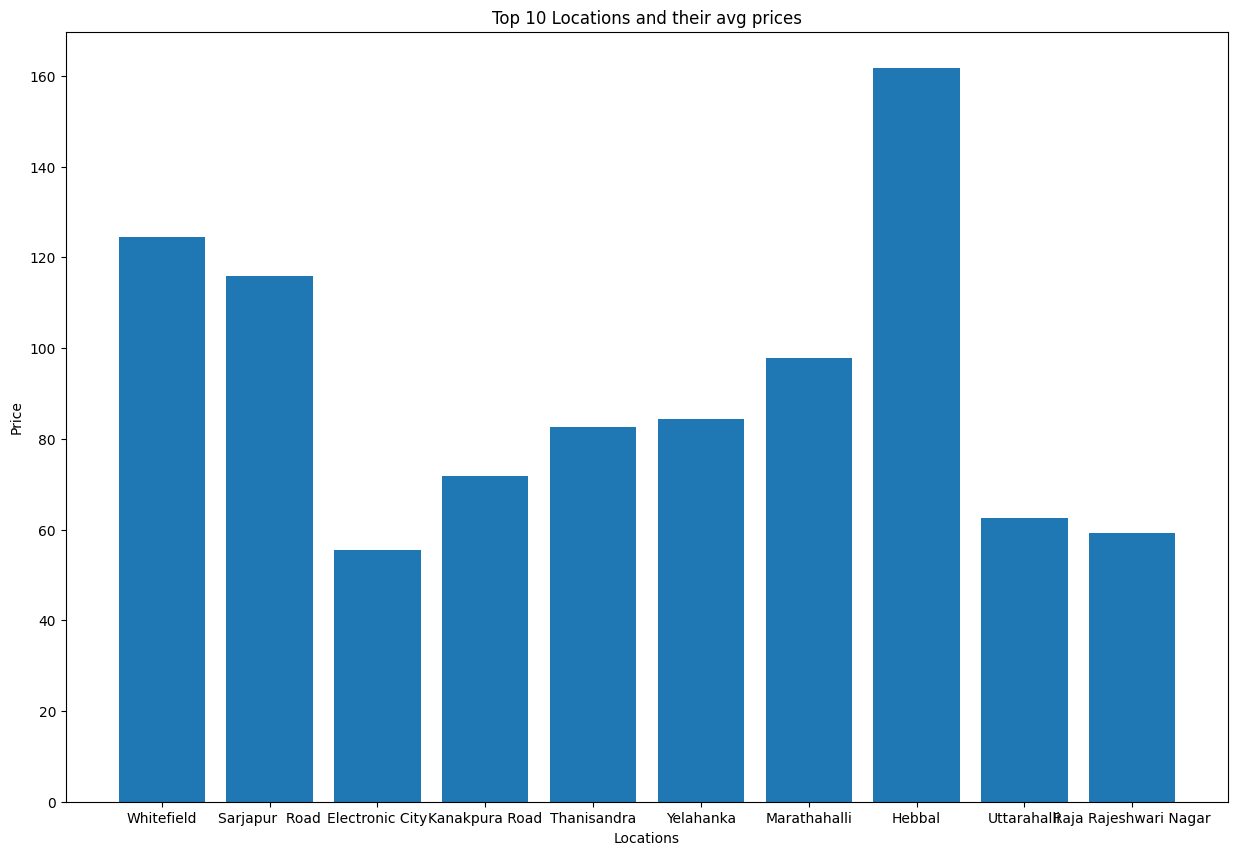

In [62]:
plt.figure(figsize=(15,10))
plt.title("Top 10 Locations and their avg prices")
plt.xlabel("Locations")
plt.ylabel("Price")
plt.bar(data=result, x = 'location', height='avg_price')
plt.show()

Most availability in Year

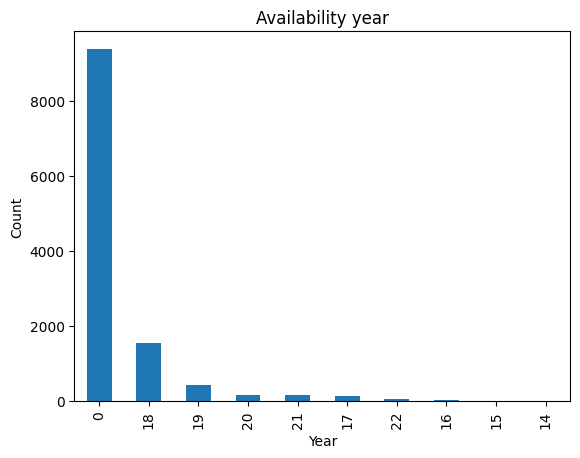

In [63]:
df['availability_year'].value_counts().plot(kind = 'bar')
plt.title("Availability year")
plt.xlabel("Year")
plt.ylabel("Count")
plt.show()

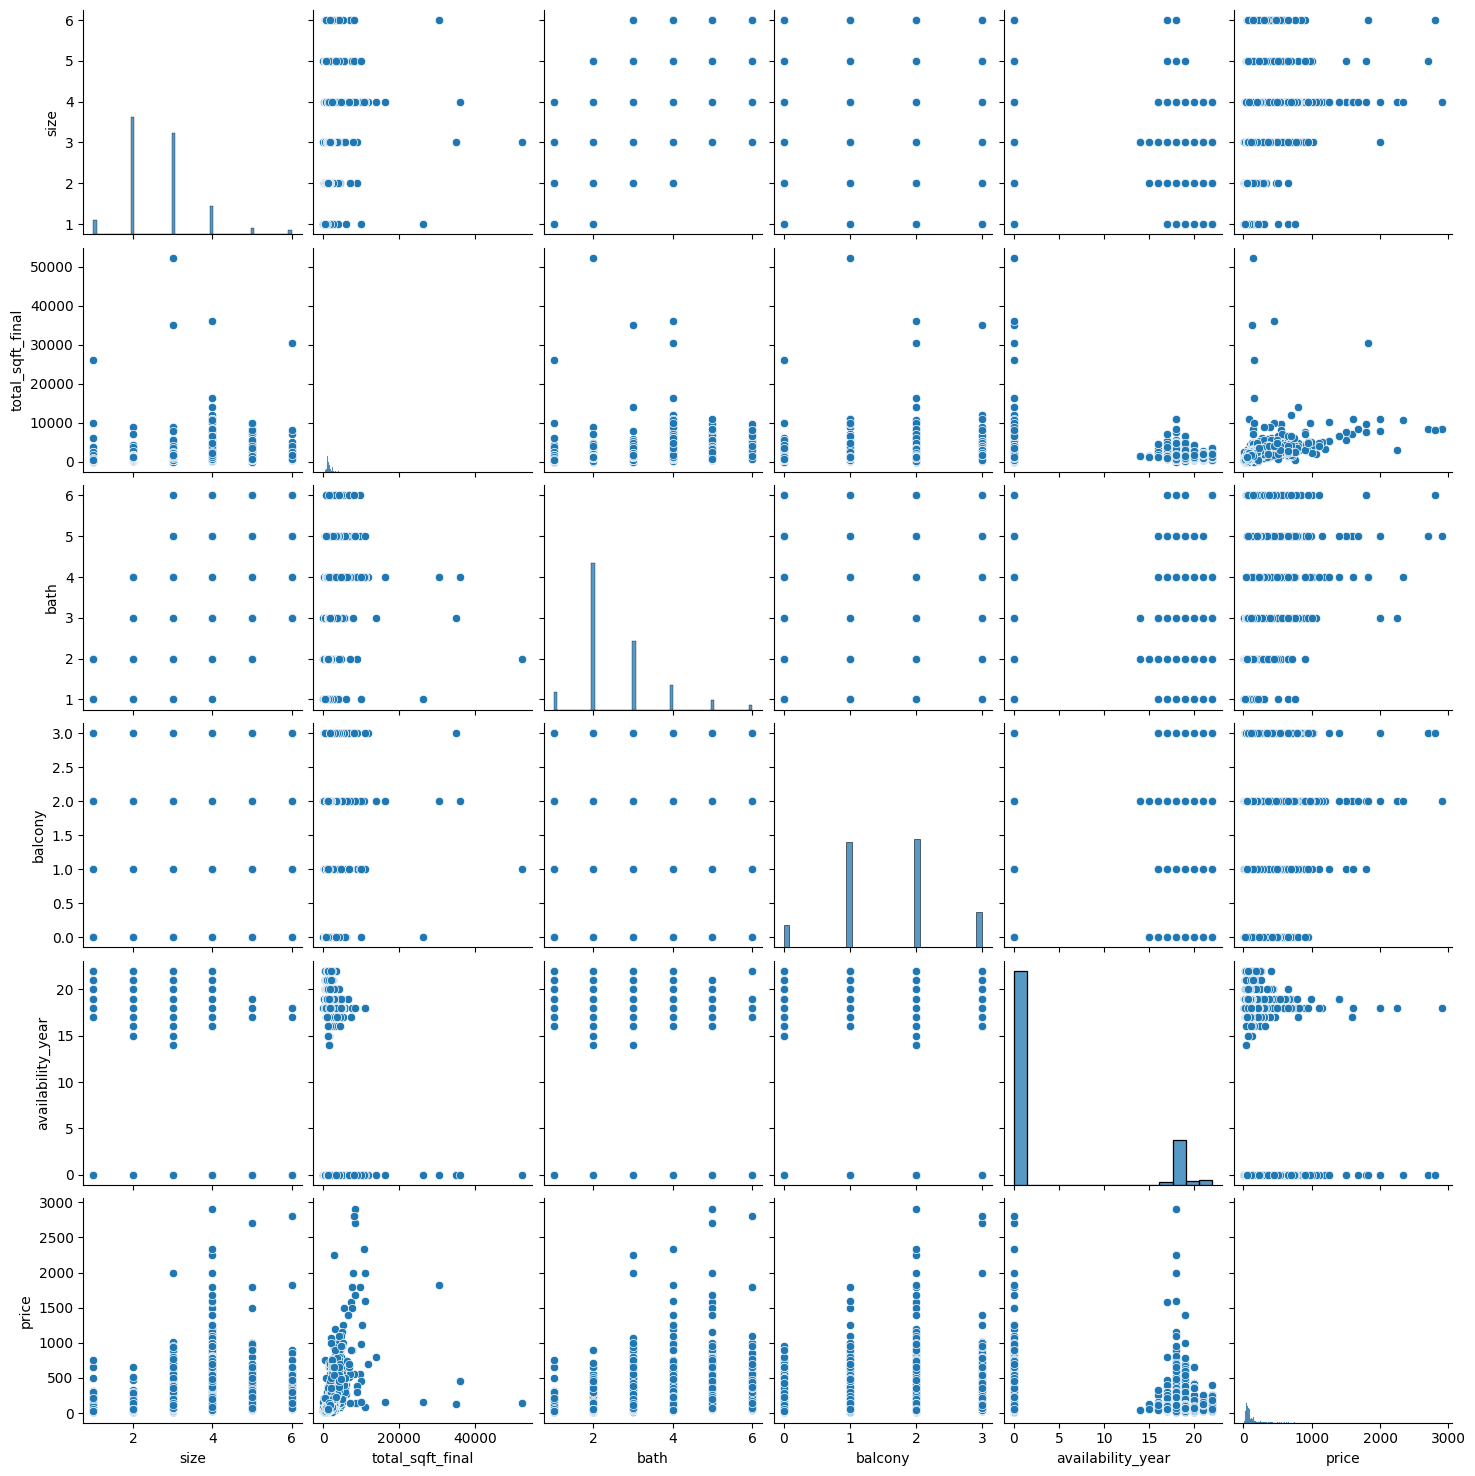

In [64]:
sns.pairplot(df)

In [65]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11877 entries, 0 to 11876
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   area_type           11877 non-null  object 
 1   location            11877 non-null  object 
 2   size                11877 non-null  int32  
 3   total_sqft_final    11877 non-null  float64
 4   bath                11877 non-null  float64
 5   balcony             11877 non-null  float64
 6   availability_year   11877 non-null  int32  
 7   availability_month  11877 non-null  object 
 8   price               11877 non-null  float64
dtypes: float64(4), int32(2), object(3)
memory usage: 742.4+ KB


In [66]:
area_df = pd.get_dummies(df['area_type'], dtype=int)
df = pd.concat([area_df,df],axis=1)

In [67]:
avail_month_df = pd.get_dummies(df['availability_month'], dtype=int)
df = pd.concat([df,avail_month_df],axis =1)

In [68]:
df

,Built-up Area,Carpet Area,Plot Area,Super built-up Area,area_type,location,size,total_sqft_final,bath,balcony,...,Feb,Jan,Jul,Jun,Mar,May,Nov,Oct,Sep,ready to move
0,0,0,0,1,Super built-up Area,Electronic City Phase II,2,1056.0,2.0,1.0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,1,0,Plot Area,Chikka Tirupathi,4,2600.0,5.0,3.0,...,0,0,0,0,0,0,0,0,0,1
2,1,0,0,0,Built-up Area,Uttarahalli,3,1440.0,2.0,3.0,...,0,0,0,0,0,0,0,0,0,1
3,0,0,0,1,Super built-up Area,Lingadheeranahalli,3,1521.0,3.0,1.0,...,0,0,0,0,0,0,0,0,0,1
4,0,0,0,1,Super built-up Area,Kothanur,2,1200.0,2.0,1.0,...,0,0,0,0,0,0,0,0,0,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11872,0,0,0,1,Super built-up Area,Bellandur,2,1262.0,2.0,2.0,...,0,0,0,0,0,0,0,0,0,1
11873,0,0,0,1,Super built-up Area,Green Glen Layout,3,1715.0,3.0,3.0,...,0,0,0,0,0,0,0,0,0,1
11874,1,0,0,0,Built-up Area,Whitefield,5,3453.0,4.0,0.0,...,0,0,0,0,0,0,0,0,0,1
11875,1,0,0,0,Built-up Area,Raja Rajeshwari Nagar,2,1141.0,2.0,1.0,...,0,0,0,0,0,0,0,0,0,1


In [69]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 11877 entries, 0 to 11876
Data columns (total 26 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Built-up  Area        11877 non-null  int32  
 1   Carpet  Area          11877 non-null  int32  
 2   Plot  Area            11877 non-null  int32  
 3   Super built-up  Area  11877 non-null  int32  
 4   area_type             11877 non-null  object 
 5   location              11877 non-null  object 
 6   size                  11877 non-null  int32  
 7   total_sqft_final      11877 non-null  float64
 8   bath                  11877 non-null  float64
 9   balcony               11877 non-null  float64
 10  availability_year     11877 non-null  int32  
 11  availability_month    11877 non-null  object 
 12  price                 11877 non-null  float64
 13  Apr                   11877 non-null  int32  
 14  Aug                   11877 non-null  int32  
 15  Dec                

In [70]:
df.drop(columns = ['area_type','availability_month' ],axis = 1, inplace = True)

In [71]:
location_count = df['location'].value_counts()

rare_locations = location_count[location_count <= 10].index

df['location'] = df['location'].replace(rare_locations, 'Other')

In [72]:
df['location'].value_counts()

Other                     2811
Whitefield                 496
Sarjapur  Road             352
Electronic City            284
Kanakpura Road             229
                          ... 
Gollarapalya Hosahalli      11
Bommenahalli                11
Karuna Nagar                11
Banjara Layout              11
Chikkabanavar               11
Name: location, Length: 217, dtype: int64

In [73]:
location_dummies = pd.get_dummies(df['location'], dtype=int)
location_dummies


,Devarachikkanahalli,1st Phase JP Nagar,2nd Stage Nagarbhavi,5th Phase JP Nagar,6th Phase JP Nagar,7th Phase JP Nagar,8th Phase JP Nagar,9th Phase JP Nagar,AECS Layout,Abbigere,...,Varthur Road,Vidyaranyapura,Vijayanagar,Vittasandra,Whitefield,Yelachenahalli,Yelahanka,Yelahanka New Town,Yelenahalli,Yeshwanthpur
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11872,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
11873,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
11874,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,1,0,0,0,0,0
11875,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [74]:
df = df[['Built-up  Area', 'Carpet  Area', 'Plot  Area', 'Super built-up  Area',
       'location', 'size', 'total_sqft_final', 'bath', 'balcony',
       'availability_year', 'Apr', 'Aug', 'Dec', 'Feb', 'Jan', 'Jul',
       'Jun', 'Mar', 'May', 'Nov', 'Oct', 'Sep', 'ready to move', 'price']]
df

,Built-up Area,Carpet Area,Plot Area,Super built-up Area,location,size,total_sqft_final,bath,balcony,availability_year,...,Jan,Jul,Jun,Mar,May,Nov,Oct,Sep,ready to move,price
0,0,0,0,1,Electronic City Phase II,2,1056.0,2.0,1.0,19,...,0,0,0,0,0,0,0,0,0,39.07
1,0,0,1,0,Chikka Tirupathi,4,2600.0,5.0,3.0,0,...,0,0,0,0,0,0,0,0,1,120.00
2,1,0,0,0,Uttarahalli,3,1440.0,2.0,3.0,0,...,0,0,0,0,0,0,0,0,1,62.00
3,0,0,0,1,Lingadheeranahalli,3,1521.0,3.0,1.0,0,...,0,0,0,0,0,0,0,0,1,95.00
4,0,0,0,1,Kothanur,2,1200.0,2.0,1.0,0,...,0,0,0,0,0,0,0,0,1,51.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11872,0,0,0,1,Bellandur,2,1262.0,2.0,2.0,0,...,0,0,0,0,0,0,0,0,1,47.00
11873,0,0,0,1,Green Glen Layout,3,1715.0,3.0,3.0,0,...,0,0,0,0,0,0,0,0,1,112.00
11874,1,0,0,0,Whitefield,5,3453.0,4.0,0.0,0,...,0,0,0,0,0,0,0,0,1,231.00
11875,1,0,0,0,Raja Rajeshwari Nagar,2,1141.0,2.0,1.0,0,...,0,0,0,0,0,0,0,0,1,60.00


In [75]:
y = df.iloc[:,-1:]
X = pd.concat([df,location_dummies],axis = 1)

In [76]:
y

,price
0,39.07
1,120.00
2,62.00
3,95.00
4,51.00
...,...
11872,47.00
11873,112.00
11874,231.00
11875,60.00


In [77]:
X.drop('price',axis = 1,inplace=True)

In [78]:
X

,Built-up Area,Carpet Area,Plot Area,Super built-up Area,location,size,total_sqft_final,bath,balcony,availability_year,...,Varthur Road,Vidyaranyapura,Vijayanagar,Vittasandra,Whitefield,Yelachenahalli,Yelahanka,Yelahanka New Town,Yelenahalli,Yeshwanthpur
0,0,0,0,1,Electronic City Phase II,2,1056.0,2.0,1.0,19,...,0,0,0,0,0,0,0,0,0,0
1,0,0,1,0,Chikka Tirupathi,4,2600.0,5.0,3.0,0,...,0,0,0,0,0,0,0,0,0,0
2,1,0,0,0,Uttarahalli,3,1440.0,2.0,3.0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,1,Lingadheeranahalli,3,1521.0,3.0,1.0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,1,Kothanur,2,1200.0,2.0,1.0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11872,0,0,0,1,Bellandur,2,1262.0,2.0,2.0,0,...,0,0,0,0,0,0,0,0,0,0
11873,0,0,0,1,Green Glen Layout,3,1715.0,3.0,3.0,0,...,0,0,0,0,0,0,0,0,0,0
11874,1,0,0,0,Whitefield,5,3453.0,4.0,0.0,0,...,0,0,0,0,1,0,0,0,0,0
11875,1,0,0,0,Raja Rajeshwari Nagar,2,1141.0,2.0,1.0,0,...,0,0,0,0,0,0,0,0,0,0


In [79]:
X = X.drop('location', axis=1)

In [80]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.25,random_state=42)


In [81]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [82]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso,ElasticNet,LassoCV,RidgeCV
from sklearn.preprocessing import PolynomialFeatures

linear = LinearRegression()
ridge = Ridge()
lasso = Lasso()
elast = ElasticNet()
lassocv = LassoCV()
ridgecv = RidgeCV()
poly = PolynomialFeatures(degree=2)

In [83]:
linear.fit(X_train_scaled,y_train)


LinearRegression()

In [84]:
y_pred_linear = linear.predict(X_test_scaled)

In [85]:
from sklearn.metrics import mean_absolute_error,mean_absolute_error,r2_score
linear_mae = mean_absolute_error(y_test,y_pred_linear)
linear_score = r2_score(y_test,y_pred_linear)

print("Linear MAE: ",linear_mae)
print("Linear Score: ",linear_score)

Linear MAE:  39.24556195953043
Linear Score:  0.4914629093984143


In [86]:
ridge.fit(X_train_scaled,y_train)
y_pred_ridge = ridge.predict(X_test_scaled)
ridge_mae = mean_absolute_error(y_test,y_pred_ridge)
ridge_score = r2_score(y_test,y_pred_ridge)

print("Ridge MAE: ", ridge_mae)
print("Ridge Score: ", ridge_score)

Ridge MAE:  39.17930763858788
Ridge Score:  0.4916606118746282


In [87]:
lasso.fit(X_train_scaled,y_train)
y_pred_lasso = lasso.predict(X_test_scaled)
lasso_mae = mean_absolute_error(y_test,y_pred_lasso)
lasso_score = r2_score(y_test,y_pred_lasso)

print("Lasso MAE: ", lasso_mae)
print("Lasso Score: ", lasso_score)

Lasso MAE:  38.50885685862557
Lasso Score:  0.4883993513961117


In [88]:
elast.fit(X_train_scaled,y_train)
y_pred_elast = elast.predict(X_test_scaled)
elast_mae = mean_absolute_error(y_test,y_pred_elast)
elast_score = r2_score(y_test,y_pred_elast)

print("Elast MAE: ", elast_mae)
print("Elast Score: ", elast_score)

Elast MAE:  39.46020770817687
Elast Score:  0.4401786522798845


In [89]:
ridgecv.fit(X_train_scaled,y_train)
y_pred_ridgecv = ridgecv.predict(X_test_scaled)
ridgecv_mae = mean_absolute_error(y_test,y_pred_ridgecv)
ridgecv_score = r2_score(y_test,y_pred_ridgecv)

print("RidgeCV MAE: ", ridgecv_mae)
print("RidgeCV Score: ", ridgecv_score)

RidgeCV MAE:  39.169481531689065
RidgeCV Score:  0.4916103770463134


In [90]:
lassocv.fit(X_train_scaled,y_train)
y_pred_lassocv = lassocv.predict(X_test_scaled)
lassocv_mae = mean_absolute_error(y_test,y_pred_lassocv)
lassocv_score = r2_score(y_test,y_pred_lassocv)

print("LassoCV MAE: ", lassocv_mae)
print("LassoCV Score: ", lassocv_score)

c:\Users\karth\env\lib\site-packages\sklearn\linear_model\_coordinate_descent.py:1571: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


LassoCV MAE:  38.54694829848687
LassoCV Score:  0.4925584629854295


In [91]:
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

In [92]:
print(X_train.shape)
print(X_test.shape)
print(poly.degree)

(8907, 239)
(2970, 239)
2


In [93]:
print(X_train.shape[1])

239


In [94]:
print(X_train.shape)
print(X_test.shape)

(8907, 239)
(2970, 239)


In [ ]:
poly_reg = LinearRegression()
poly_reg.fit(X_train_poly,y_train)
y_pred_poly = poly_reg.predict(X_test_poly)

poly_mae = mean_absolute_error(y_test,y_pred_poly)
poly_score = r2_score(y_test,y_pred_poly)

print("PolyMAE: ", poly_mae)
print("Poly Score: ", poly_score)